# <font color=blue>OPTIM/OPTECH Laboratory Learning Session III: </font> 
## <font color=blue>MULTI-OBJECTIVE OPTIMIZATION</font> 

### `MASTEAM`: Master's degree in Applied Telecommunications and Engineering Management
### `MATT`: Master's degree in Advanced Telecommunication Technologies
### `CoDaS`: Erasmus Mundus master's degree in Communications, Engineering and Data Science
### `AI4CI`: Master's degree in Artificial Intelligence for Connected Industries


###  <font color=#922B21>Castelldefels School of Telecommunications and Aerospace Engineering (EETAC)</font>

**<font color=teal>Cristina Cervelló-Pastor (cristina.cervello@upc.edu)</font>**

## <font color=green><b> Multi-Objective to Balance Multihoming Loads in Heterogeneous Wireless Networks</b></font>


In this session we address the problem about the 'always best connected' problem in heterogeneus wireless 
networks.

We propose a multi-objective optimization model to achieve a balanced distribution of connections to 
multiple access networks in order to allocate, in a fair way, the available resources in a network. It is considered the possibility of the simultaneous use of multiple network interfaces by each mobile device.

We will take into account three key indicators, that we would like to minimize: 

<ol>
<li>Load of access networks,
<li>Cost of connections and,
<li>Battery consumption due to connections.
</ol>

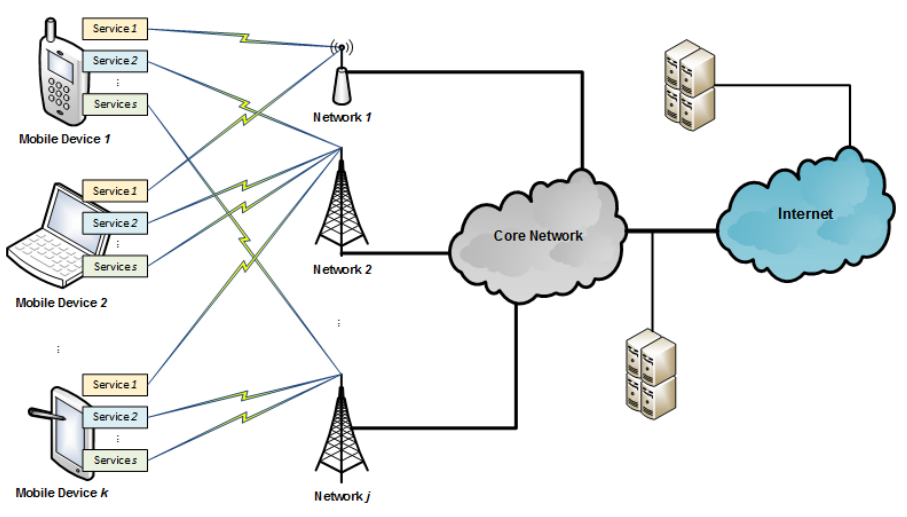

In [82]:
from IPython.display import Image 
Image(filename='./MultihomingCellularNet.png',width=500, height=500)

## <font color=blue><b> MODEL TO IMPLEMENT</b></font> ##

#### <font color=blue><b> PARAMETERS:</b></font> ####
$N$ Set of access networks
<br /> <br /> 
$M$ set of mobile devices
<br /> <br /> 
$S$ set of services
<br /> <br /> 

##### Parameters related to services:
<br />
$D_s$ Typical demand of each service
<br /> <br /> 
$B_s$ BW needed for each service
<br /> <br /> 
$C_s$ Cost of each service

##### Parameters related to mobile devices:
<br />
$PW_{m,n}$ Power consumption of each device $m$ when connected to each network $n$
<br /> <br /> 
$SI_{m,n}$ Signal Information: perceived signal of each kind of access network $n$ by mobile devices $m$
<br /> <br /> 
$MC_m$ Maximum cost incurred by the user in the contract of mobile device $m$
<br /> <br /> 
$R_m$ Set of services of mobile device $m$
<br /> <br /> 
$BT_m$ Current remaining battery of each mobile device $m$
<br /> <br /> 
$SS$ Minimum signal strength required by any mobile device to connect to any network
<br /> <br /> 

#### <font color=blue><b> VARIABLES:</b></font> ####

$y_{mn}$=$\left\{
            \begin{array}{ll}
              1, & \hbox{if mobile device $m$ connects to network $n$} \\
              0, & \hbox{otherwise.}
            \end{array}
          \right.$
<br /> <br />  
$x_{mn}^s$=$\left\{
            \begin{array}{ll}
              1, & \hbox{if mobile device $m$ connects to network $n$ to satisfy service $s$} \\
              0, & \hbox{otherwise.}
            \end{array}
          \right.$
<br /> <br /> 
$\alpha$ Maximum load of the networks
<br /> <br /> 
$\beta$ Maximum connection cost to the networks
<br /> <br /> 
$\gamma$ Maximum battery consumption
<br /> <br /> 

#### <font color=blue><b> MODEL:</b></font> ####

\begin{alignat*}{}
&\mbox{minimize }  \quad \quad \quad \alpha&& \\
&\mbox{minimize }  \quad \quad \quad \beta&& \\
&\mbox{minimize } \quad \quad \quad \gamma&& \\
&\\
&\textbf{subject to:} &\nonumber\\[8pt]
&\textbf{(1)}\small{\mbox{ Determine if a mobile device connects to a network to satisfy the demand of its services, or not}}&&\nonumber\\
&\qquad y_{mn} \leq \sum_{\forall s\in S | s\in R_m}x_{mn}^s \qquad\qquad\forall m\in M,\ \forall n\in N\quad\nonumber\\
&\\
&\textbf{(2)}\small{\mbox{ For connecting to a network, first the device
 has to be connected to the network}}&&\nonumber\\
&\qquad x_{mn}^s \leq y_{mn}\qquad\qquad\forall m\in M,\ \forall n\in N,\ \forall s\in S\quad&\nonumber\\
&\\
&\textbf{(3)}\small{\mbox{ Guarantee the accessibility of the services in every mobile device to one network}}&&\nonumber\\
&\qquad \sum_{\forall n\in N}x_{mn}^s = 1 \qquad\qquad\forall m\in M,\ \forall s\in S| s\in R_m\quad\nonumber\\
&\\
&\textbf{(4)}\small{\mbox{ Guarantee that the services being used can only be provided by networks with enough bandwidth}}\nonumber\\
&\small{\mbox{ to meet its demand, not overloading any network}}\nonumber\\
&\qquad D_s\cdot x_{mn}^s \leq B_s\qquad\qquad\forall m\in M,\ \forall n\in N,\ \forall s\in S| s\in R_m\nonumber\\
&\\
&\textbf{(5)}\small{\mbox{ Guarantee that the connection cost to a network does not exceed the maximum connection
cost}}\nonumber\\
&\qquad C_s\cdot y_{mn} \leq MC_m\qquad\qquad\forall m\in M,\ \forall n\in N\nonumber\\
&\\
&\textbf{(6)}\small{\mbox{ Ensure that the consumption indicator generated by the connection to a network 
 does not exceed the battery level of a mobile device}}\nonumber\\
&\qquad PW_{m,n}\cdot y_{mn} \leq BT_m\qquad\qquad\forall m\in M,\ \forall n\in N\nonumber\\
 &\\
 &\textbf{(7)}\small{\mbox{ Guarantee the connection of a mobile device to a reachable network (with enough signal strength)
}}\nonumber\\
&\qquad SS\cdot y_{mn} \leq SI_m\qquad\qquad\forall m\in M,\ \forall n\in N\nonumber\\
 &\\
 &\textbf{(8)}\small{\mbox{ Calculate the maximum load of the available networks}}\nonumber\\
&\qquad \sum_{\forall s\in S | s\in R_m}\sum_{\forall m\in M} \frac{D_s\cdot x_{m,n}^s}{B_s}\leq \alpha \qquad\qquad\forall n\in N\nonumber\\
 &\\
&\textbf{(9)}\ \small{\mbox{ Calculate the maximum connection cost to the networks}}\nonumber\\
&\qquad\sum_{\forall m\in M} C_s\cdot y_{m,n}\leq \beta\qquad\qquad\forall n\in N\nonumber\\
&\\
&\textbf{(10)}\small{\mbox{ Calculate the maximum power consumption indicator due to connection to networks
}}\nonumber\\
&\qquad\ \sum_{\forall m\in M} PW_{m,n}\cdot y_{m,n}\leq \gamma \qquad\qquad\forall n\in N \nonumber\\
&\\
&\textbf{(11)}\small{\mbox{ Variables definition}}\nonumber\\
&\qquad  x_{mn}^s,\ y_{mn}\ \mbox{binary} \qquad\qquad  \forall m\in M,\ \forall n\in N,\ \forall s\in S\nonumber\\
&\qquad  \alpha,\ \beta,\ \gamma\ \geq 0, \ \mbox{real.}\nonumber&&\\
\end{alignat*}

### <font color=blue><b> PROBLEM FORMULATION</b></font>

In [83]:
'''NETWORKS'''
# Number of access network
NumAccNets = 3  # LTE, WiFi, HSPA+

# Networks: LTE, WiFi, HSPA+ (High-Speed Packet Access)
AccessNetworks = ['LTE', 'WiFi', 'HSPA+']


'''SERVICES'''
# Services Demand (Mb/s)
NumServices = 3
Services = ['voice', 'video', 'web']
Demand = [0.1, 3, 0.5]

# Typical BW (Mb/s) for each technology (download speed)
BW = [36, 54, 15]

# Cost of connection to each acess network (monetary unit)
Cost = [80,0,40]


'''MOBILE USERS INFORMATION'''

# Number of mobiles in our scenario
NumMobiles = 5


# Mobile devices information: service interfaces, max cost, current of % battery of each device
MobInfo = {
    1: {'voice':1, 'video':1, 'web':0, 'maxcost':62, 'percentagebattery':85},
    2: {'voice':1, 'video':0, 'web':1, 'maxcost':44, 'percentagebattery':34},
    3: {'voice':1, 'video':1, 'web':1, 'maxcost':98, 'percentagebattery':74},
    4: {'voice':1, 'video':0, 'web':1, 'maxcost':73, 'percentagebattery':28},
    5: {'voice':1, 'video':1, 'web':1, 'maxcost':82, 'percentagebattery':50}
}


# Perceived signal of each kind of access network by mobile devices
# LTE, WiFi, HSPA+
SignalInfo = {
    1: [87,78,64],
    2: [55,68,28],
    3: [92,47,88],
    4: [0 ,85,25],
    5: [91,95,93],
}


# Minimum signal strength required by any mobile device to connect to any network
ms = 20


# Indicator of the battery percentage remaining in mobile device.
# It takes a high value (i.e., 3) if the battery % is above a 
# battery-percentage upper limit ub;
# it takes a low value (i.e., 1) if the battery % is bellow a 
# battery-percentage lower limit lb; 
# finally, it takes a medium value (i.e., 2), if 
# the battery % is between lb and ub.

Battery=[0 for m in range(NumMobiles)]
lb=10 # battery-percentage lower limit
ub=80 # battery-percentage upper limit
for m in range(NumMobiles):
    if MobInfo[m+1]['percentagebattery']<lb: Battery[m]=1
    elif MobInfo[m+1]['percentagebattery']<=ub: Battery[m]=2
    else: Battery[m]=3
        
        
# Power consumption indicator.
# To model the power consumption generated in a mobile device when connected to a network
# we use a power consumption indicator that relates the signal strength perceived by the device.
# The power consumption indicator is inversely proportional to the signal strength
# perceived; it is low (i.e., 1) if the perceived signal is above a signal upper limit us; high (i.e., 3)
# if the perceived signal is below a signal lower limit ls; and medium (i.e., 2) if it lays between ls
# and us.

PowerConsumption=[ [ 0 for n in range(NumAccNets) ] for m in range(NumMobiles) ]
ls=40 # signal lower limit
us=85 # signal upper limit
for m in range(NumMobiles):
    for n in range(NumAccNets):
        if SignalInfo[m+1][n]>us: PowerConsumption[m][n]=1
        elif SignalInfo[m+1][n]>=ls: PowerConsumption[m][n]=2
        else: PowerConsumption[m][n]=3

### <font color=blue><b> MODEL</b></font>

In [84]:
from pyomo.environ import *
from pyomo.opt import SolverFactory
from pyomo.core import Var

######################
## CREATE THE MODEL ##
######################

model = AbstractModel()


######################
## MODEL PARAMETERS ##
######################

# Set of access networks
model.N = RangeSet(1,NumAccNets)

# Set of mobile devices
model.M = RangeSet(1,NumMobiles)

# Set of services
model.S = RangeSet(1,NumServices)


#####################
## MODEL VARIABLES ##
#####################

# y[m,n]=1 if mobile m connects to the network n, and 0 otherwise
model.y = Var(model.M, model.N, within=Binary, initialize=0)

# x[m,n,s]=1 if mobile m connects to the network n to satisfy service s, and 0 otherwise
model.x = Var(model.M, model.N, model.S, within=Binary, initialize=0)

# Maximum load of the networks
model.alpha = Var(within=NonNegativeReals, initialize=0)

# Maximum connection cost to the networks
model.beta  = Var(within=NonNegativeReals, initialize=0)

# Maximum battery consumption indicator from connections to the networks
model.gamma = Var(within=NonNegativeReals, initialize=0)


########################
## OBJECTIVE FUNCTION ##
########################

'''OBJECTIVE FUNCTION 1'''
# Minimize the maximum load of the networks
def Objective1_rule(model):
    return model.alpha
model.Objective1 = Objective(rule=Objective1_rule, sense=minimize)

'''OBJECTIVE FUNCTION 2'''
# Minimize the maximum connection cost to the networks
def Objective2_rule(model):
    return model.beta
model.Objective2 = Objective(rule=Objective2_rule, sense=minimize)

'''OBJECTIVE FUNCTION 3'''
# Minimize the maximum battery consumption of the networks
def Objective3_rule(model):
    return model.gamma
model.Objective3 = Objective(rule=Objective3_rule, sense=minimize)


# ACTIVATE OR DEACTIVATE the objective function according the exercise

model.Objective1.deactivate()
model.Objective2.deactivate()
model.Objective3.activate()


#################
## CONSTRAINTS ##
#################

'''CONSTRAINT 1'''
# Determine if a mobile device connects to a network to satisfy the demand of its services, or not.
def C1_rule(model,m,n):
    return model.y[m,n] <= sum(model.x[m,n,s] for s in model.S if MobInfo[m][Services[s-1]]==1)

model.C1 = Constraint(model.M, model.N,rule=C1_rule)


'''CONSTRAINT 2'''
# For connecting to a network to satisfy one of its service demand, the device
# has to be connected to the network
def C2_rule(model,m,n,s):
    return model.x[m,n,s] <= model.y[m,n] 

model.C2 = Constraint(model.M, model.N, model.S, rule=C2_rule)


'''CONSTRAINT 3'''
# To guarantee the accessibility of the services in every mobile device to one network
def C3_rule(model,m,s):
    if MobInfo[m][Services[s-1]]==1:
        return sum(model.x[m,n,s] for n in model.N)==1
    else:
        return Constraint.Skip

model.C3 = Constraint(model.M, model.S,rule=C3_rule)


'''CONSTRAINT 4'''
# To guarantee that the services being used can only be provided by networks with enough 
# bandwidth to meet its demand, not overloading any network.
def C4_rule(model,m,n,s):
    if MobInfo[m][Services[s-1]]==1:
        return Demand[s-1]*model.x[m,n,s] <= BW[s-1]
    else:
        return Constraint.Skip

model.C4 = Constraint(model.M, model.N, model.S, rule=C4_rule)


'''CONSTRAINT 5'''
# To guarantee that the connection cost to a network does not exceed the maximum connection
#cost established by the user of the mobile device
def C5_rule(model,m,n):
    if Cost[n-1] !=0:
        return Cost[n-1]*model.y[m,n] <= MobInfo[m]['maxcost']
    else:
        return Constraint.Skip

model.C5 = Constraint(model.M, model.N, rule=C5_rule)


'''CONSTRAINT 6'''
# To ensure that the consumption indicator generated by the connection to a network 
# does not exceed the battery level of a mobile device.
def C6_rule(model,m,n):
    return PowerConsumption[m-1][n-1]*model.y[m,n] <= Battery[m-1]

model.C6 = Constraint(model.M, model.N, rule=C6_rule)


'''CONSTRAINT 7'''
# To guarantee the connection of a mobile device to a reachable network.
def C7_rule(model,m,n):
    return ms*model.y[m,n] <= SignalInfo[m][n-1]

model.C7 = Constraint(model.M, model.N, rule=C7_rule)


'''CONSTRAINT 8'''
# To calculate the maximum load of the available networks.
def C8_rule(model,n):
    return sum((Demand[s-1]/BW[s-1])*model.x[m,n,s]for m in model.M \
               for s in model.S if MobInfo[m][Services[s-1]]==1) <= model.alpha

model.C8 = Constraint(model.N, rule=C8_rule)


'''CONSTRAINT 9'''
# To calculate the maximum connection cost to the networks.
def C9_rule(model,n):
    return sum(Cost[n-1]*model.y[m,n] for m in model.M) <= model.beta

model.C9 = Constraint(model.N, rule=C9_rule)


'''CONSTRAINT 10'''
# To calculate the maximum power consumption indicator due to connection to networks.
def C10_rule(model,n):
    return sum(PowerConsumption[m-1][n-1]*model.y[m,n] for m in model.M)<= model.gamma

model.C10 = Constraint(model.N, rule=C10_rule)

#### SOLVE THE MODEL

In [85]:
# Construct the instance of the model and pass it to an (external) solver, in this case GLPK
opt = SolverFactory('glpk')
instance = model.create_instance()
results = opt.solve(instance)

#### GET THE RESULTS

In [86]:
# Basically we are interesting in alpha, beta and gamma values

print('Maximum load of the networks (\u03B1):','{:.2f}'.format(instance.alpha.value*100),'%')
print('Maximum connection cost to the networks (\u03B2):',instance.beta.value)
print('Maximum consumption indicator from connections to the networks (\u03B3):',instance.gamma.value)


Maximum load of the networks (α): 15.00 %
Maximum connection cost to the networks (β): 80.0
Maximum consumption indicator from connections to the networks (γ): 4.0


In [87]:
# Values of these metrics on each technology 
print('LOAD (\u03B1)')
for n in range(1,NumAccNets+1):
    print('  ',AccessNetworks[n-1],'{:.2f}'.format(sum((Demand[s-1]/BW[s-1])*instance.x[m,n,s].value*100 \
                                                for m in instance.M 
                                                for s in instance.S if MobInfo[m][Services[s-1]]==1)),'%')

print('COST (\u03B2)')
for n in range(1,NumAccNets+1):
    print('  ',AccessNetworks[n-1],sum(Cost[n-1]*instance.y[m,n].value for m in instance.M))
    
    
print('BATTERY CONSUMPTION (\u03B3)')
for n in range(1,NumAccNets+1):
    print('  ',AccessNetworks[n-1],sum(PowerConsumption[m-1][n-1]*instance.y[m,n].value for m in instance.M))

LOAD (α)
   LTE 9.17 %
   WiFi 7.22 %
   HSPA+ 15.00 %
COST (β)
   LTE 80.0
   WiFi 0.0
   HSPA+ 80.0
BATTERY CONSUMPTION (γ)
   LTE 1.0
   WiFi 4.0
   HSPA+ 3.0


In [88]:
# See how mobile devices are connected to each technology for each service.
for n in instance.N:
    print('Network',AccessNetworks[n-1])
    for m in instance.M:
        if instance.y[m,n].value==1:  
            print('    mobile',m,'Battery Consumption:',PowerConsumption[m-1][n-1] )
            for s in instance.S:
                if instance.x[m,n,s].value==1:
                    print('       ', Services[s-1],'service' '-->', \
                           'load:','{:.2f}'.format(Demand[s-1]/BW[s-1]*100),'%',\
                           'cost:',Cost[n-1] )

Network LTE
    mobile 3 Battery Consumption: 1
        voice service--> load: 0.28 % cost: 80
        video service--> load: 5.56 % cost: 80
        web service--> load: 3.33 % cost: 80
Network WiFi
    mobile 2 Battery Consumption: 2
        voice service--> load: 0.28 % cost: 0
        web service--> load: 3.33 % cost: 0
    mobile 4 Battery Consumption: 2
        voice service--> load: 0.28 % cost: 0
        web service--> load: 3.33 % cost: 0
Network HSPA+
    mobile 1 Battery Consumption: 2
        voice service--> load: 0.28 % cost: 40
        video service--> load: 5.56 % cost: 40
    mobile 5 Battery Consumption: 1
        voice service--> load: 0.28 % cost: 40
        video service--> load: 5.56 % cost: 40
        web service--> load: 3.33 % cost: 40


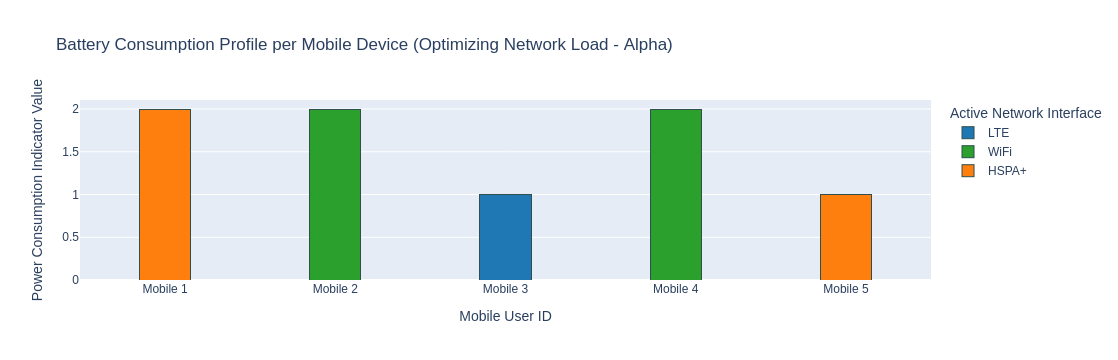

In [89]:
import pandas as pd
import plotly.express as px
import numpy as np

# 1. Create a list to collect battery metrics
battery_data = []

# Loop through networks and mobiles
for n in instance.N:
    network_name = AccessNetworks[n-1]
    for m in instance.M:
        if value(instance.y[m,n]) > 0.5:  
            battery_indicator = PowerConsumption[m-1][n-1]
            
            battery_data.append({
                "Mobile Device": f"Mobile {m}",
                "Access Network": network_name,
                "Battery Consumption Indicator": battery_indicator
            })

# 2. Convert to a DataFrame
df_battery = pd.DataFrame(battery_data)

# 3. Explicitly define the ordered sequence for the X axis
mobile_order = [f"Mobile {m}" for m in range(1, NumMobiles + 1)]

# 4. Generate the interactive Stacked Bar Chart with custom options
fig_battery = px.bar(
    df_battery, 
    x="Mobile Device", 
    y="Battery Consumption Indicator", 
    color="Access Network", 
    title="Battery Consumption Profile per Mobile Device (Optimizing Network Load - Alpha)",
    color_discrete_map={'LTE': '#1f77b4', 'WiFi': '#2ca02c', 'HSPA+': '#ff7f0e'}, # Matches the traffic chart colors
    category_orders={"Mobile Device": mobile_order}
)

# 5. Make the bars narrower
fig_battery.update_traces(
    width=0.3, 
    marker=dict(line=dict(width=1, color='DarkSlateGrey'))
)

# 6. Refine layout styling for publishing quality
fig_battery.update_layout(
    xaxis_title="Mobile User ID",
    yaxis_title="Power Consumption Indicator Value",
    legend_title="Active Network Interface",
    barmode="stack",
    hovermode="x"
)

fig_battery.show()

#### PLOT THE RESULTS

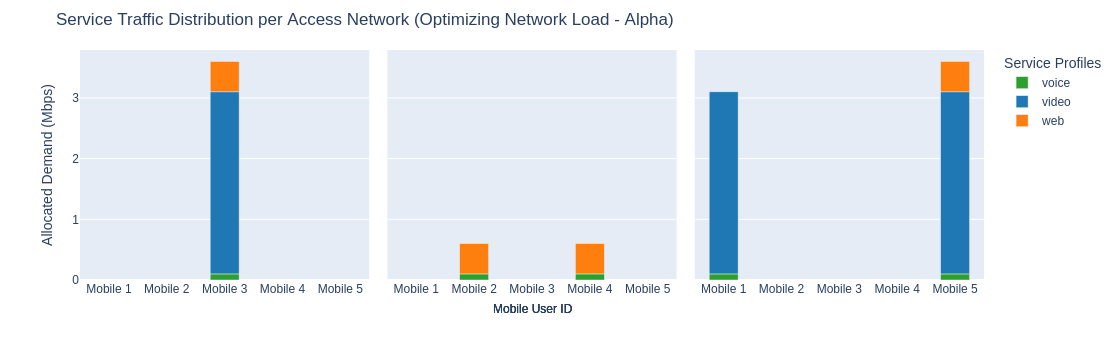

In [90]:
import matplotlib.pyplot as plt
import plotly.express as px
import pandas as pd
import numpy as np

# 1. Extract the active assignments from the binary variable x[m, n, s]
assignment_data = []

for m in instance.M:
    for n in instance.N:
        for s in instance.S:
            if value(instance.x[m, n, s]) > 0.5:
                assignment_data.append({
                    "Mobile": f"Mobile {m}",
                    "Access Network": AccessNetworks[n-1],
                    "Service Type": Services[s-1],
                    "Traffic Demand (Mbps)": Demand[s-1]
                })

df_plot = pd.DataFrame(assignment_data)

# 2. Fix the sorting sequence for the X axis
mobile_order = [f"Mobile {m}" for m in range(1, NumMobiles + 1)]

# 3. Create a clean Stacked Bar Chart without using confusing stripes (pattern_shape)
# Instead, we use colors for Services and separate columns (facet_col) for Networks
fig = px.bar(
    df_plot, 
    x="Mobile", 
    y="Traffic Demand (Mbps)", 
    color="Service Type", 
    facet_col="Access Network", 
    title="Service Traffic Distribution per Access Network (Optimizing Network Load - Alpha)",
    category_orders={"Mobile": mobile_order, "Access Network": AccessNetworks},
    color_discrete_map={'video': '#1f77b4', 'web': '#ff7f0e', 'voice': '#2ca02c'}
)

# Narrow the bars
fig.update_traces(width=0.5)

# Remove individual axis titles from every single subplot to avoid "Mobile" duplicates
for axis in fig.layout:
    if axis.startswith('xaxis'):
        fig.layout[axis].title.text = ""

# Refine layout styling and create a single centered X-axis title using an annotation
fig.update_layout(
    yaxis_title="Allocated Demand (Mbps)",
    legend_title="Service Profiles",
    hovermode="x",
    margin=dict(b=80, t=50),
    # Add a global centered title under the whole figure
    annotations=[
        dict(
            text="Mobile User ID",
            xref="paper", yref="paper",
            x=0.5, y=-0.17,
            showarrow=False,
            font=dict(size=12)
        )
    ]
)
        
fig.show()

### <font color=blue><b>EXERCISE 1</b></font>.- 
#### Compare the results running the model for each objective function separately. Decide if these points are part of the Pareto Front and explain why.

 <span style="color:orangered">$\underline{\hspace{ 6 in}}$</span> 

## <font color=darkgreen><b>WEIGHTED SUM METHOD</b></font>

In Weighted Sum Method the multi-objective optimization problem is
transformed into a mono-objective optimization problem. The simplest way to
proceed is to take each objective function, associate a weight with it and then
take a weighted sum of objective functions.

If weights have to be modified inside a loop, they have to be **defined as mutable parameters** in the model:

```python 
model.w1 = Param(mutable=True, initialize=0.33)
model.w2 = Param(mutable=True, initialize=0.33)
model.w3 = Param(mutable=True, initialize=0.34)
```


To obtain comparable values, we will normalize $\alpha$, $\beta$, and $\gamma$ by their maximum values (observed in previous executions). Thus, define the following parameters and use them in the objective function:

```python 
max_alpha = 
max_beta = 
max_gamma =
```


### <font color=blue><b>EXERCISE 2</b></font>.- 
#### Write the new objective function and run the model. Plot the resulting points as the weights vary and determine the Pareto front. To do this, write the complete model in the cell below and use the provided code (analyze how it works).

#### Indicate which points are part of the Pareto front and why. You can also analyse the dataframe df_solutions.

### <font color=green><b>Write $\underline{all}$ the model below</b></font>

In [91]:
from pyomo.environ import *
from pyomo.opt import SolverFactory
from pyomo.core import Var

######################
## CREATE THE MODEL ##
######################

model = AbstractModel()

max_alpha = 0.3139
max_beta = 160
max_gamma = 9

######################
## MODEL PARAMETERS ##
######################

# Set of access networks
model.N = RangeSet(1,NumAccNets)

# Set of mobile devices
model.M = RangeSet(1,NumMobiles)

# Set of services
model.S = RangeSet(1,NumServices)

model.w1 = Param(mutable=True, initialize=0.33)
model.w2 = Param(mutable=True, initialize=0.33)
model.w3 = Param(mutable=True, initialize=0.34)


#####################
## MODEL VARIABLES ##
#####################

# y[m,n]=1 if mobile m connects to the network n, and 0 otherwise
model.y = Var(model.M, model.N, within=Binary, initialize=0)

# x[m,n,s]=1 if mobile m connects to the network n to satisfy service s, and 0 otherwise
model.x = Var(model.M, model.N, model.S, within=Binary, initialize=0)

# Maximum load of the networks
model.alpha = Var(within=NonNegativeReals, initialize=0)

# Maximum connection cost to the networks
model.beta  = Var(within=NonNegativeReals, initialize=0)

# Maximum battery consumption indicator from connections to the networks
model.gamma = Var(within=NonNegativeReals, initialize=0)


########################
## OBJECTIVE FUNCTION ##
########################

'''OBJECTIVE FUNCTION 1'''
# Minimize the maximum load of the networks
def Objective1_rule(model):
    return model.alpha
model.Objective1 = Objective(rule=Objective1_rule, sense=minimize)

'''OBJECTIVE FUNCTION 2'''
# Minimize the maximum connection cost to the networks
def Objective2_rule(model):
    return model.beta
model.Objective2 = Objective(rule=Objective2_rule, sense=minimize)

'''OBJECTIVE FUNCTION 3'''
# Minimize the maximum battery consumption of the networks
def Objective3_rule(model):
    return model.gamma
model.Objective3 = Objective(rule=Objective3_rule, sense=minimize)

'''OBJECTIVE FUNCTION 4'''
# Weighted Sum Objective Function
def Objective4_rule(model):
    return model.w1/max_alpha * model.alpha + model.w2/max_beta * model.beta + (1 - model.w1 - model.w2)/max_gamma * model.gamma
model.Objective4 = Objective(rule=Objective4_rule, sense=minimize)


# ACTIVATE OR DEACTIVATE the objective function according the exercise

model.Objective1.deactivate()
model.Objective2.deactivate()
model.Objective3.deactivate()
model.Objective4.activate()

#################
## CONSTRAINTS ##
#################

'''CONSTRAINT 1'''
# Determine if a mobile device connects to a network to satisfy the demand of its services, or not.
def C1_rule(model,m,n):
    return model.y[m,n] <= sum(model.x[m,n,s] for s in model.S if MobInfo[m][Services[s-1]]==1)

model.C1 = Constraint(model.M, model.N,rule=C1_rule)


'''CONSTRAINT 2'''
# For connecting to a network to satisfy one of its service demand, the device
# has to be connected to the network
def C2_rule(model,m,n,s):
    return model.x[m,n,s] <= model.y[m,n] 

model.C2 = Constraint(model.M, model.N, model.S, rule=C2_rule)


'''CONSTRAINT 3'''
# To guarantee the accessibility of the services in every mobile device to one network
def C3_rule(model,m,s):
    if MobInfo[m][Services[s-1]]==1:
        return sum(model.x[m,n,s] for n in model.N)==1
    else:
        return Constraint.Skip

model.C3 = Constraint(model.M, model.S,rule=C3_rule)


'''CONSTRAINT 4'''
# To guarantee that the services being used can only be provided by networks with enough 
# bandwidth to meet its demand, not overloading any network.
def C4_rule(model,m,n,s):
    if MobInfo[m][Services[s-1]]==1:
        return Demand[s-1]*model.x[m,n,s] <= BW[s-1]
    else:
        return Constraint.Skip

model.C4 = Constraint(model.M, model.N, model.S, rule=C4_rule)


'''CONSTRAINT 5'''
# To guarantee that the connection cost to a network does not exceed the maximum connection
#cost established by the user of the mobile device
def C5_rule(model,m,n):
    if Cost[n-1] !=0:
        return Cost[n-1]*model.y[m,n] <= MobInfo[m]['maxcost']
    else:
        return Constraint.Skip

model.C5 = Constraint(model.M, model.N, rule=C5_rule)


'''CONSTRAINT 6'''
# To ensure that the consumption indicator generated by the connection to a network 
# does not exceed the battery level of a mobile device.
def C6_rule(model,m,n):
    return PowerConsumption[m-1][n-1]*model.y[m,n] <= Battery[m-1]

model.C6 = Constraint(model.M, model.N, rule=C6_rule)


'''CONSTRAINT 7'''
# To guarantee the connection of a mobile device to a reachable network.
def C7_rule(model,m,n):
    return ms*model.y[m,n] <= SignalInfo[m][n-1]

model.C7 = Constraint(model.M, model.N, rule=C7_rule)


'''CONSTRAINT 8'''
# To calculate the maximum load of the available networks.
def C8_rule(model,n):
    return sum((Demand[s-1]/BW[s-1])*model.x[m,n,s]for m in model.M \
               for s in model.S if MobInfo[m][Services[s-1]]==1) <= model.alpha

model.C8 = Constraint(model.N, rule=C8_rule)


'''CONSTRAINT 9'''
# To calculate the maximum connection cost to the networks.
def C9_rule(model,n):
    return sum(Cost[n-1]*model.y[m,n] for m in model.M) <= model.beta

model.C9 = Constraint(model.N, rule=C9_rule)


'''CONSTRAINT 10'''
# To calculate the maximum power consumption indicator due to connection to networks.
def C10_rule(model,n):
    return sum(PowerConsumption[m-1][n-1]*model.y[m,n] for m in model.M)<= model.gamma

model.C10 = Constraint(model.N, rule=C10_rule)

### <font color=green><b>Use the following code to execute the model with different values of weights</b></font>

In [92]:
########################## ITERATIVE LOOP TO GENERATE SOLUTIONS ############################

opt = SolverFactory('glpk')
instance = model.create_instance()

# Generate different weight combinations that always sum up to exactly 1.0

step = 0.05 # This value could be modified

solutions = []

print("Finding Solutions for different weight values...")

for w1 in np.arange(0.0, 1.01, step):
    for w2 in np.arange(0.0, 1.01 - w1, step):
        w3 = 1.0 - w1 - w2
        
        # Inject current weight distributions
        instance.w1.value = float(w1)
        instance.w2.value = float(w2)
        instance.w3.value = float(w3)
        
        results = opt.solve(instance)
        
        if (results.solver.status == SolverStatus.ok) and (results.solver.termination_condition == TerminationCondition.optimal):
            alpha_opt = value(instance.alpha)
            beta_opt = value(instance.beta)
            gamma_opt = value(instance.gamma)
            
            # Record structural values and prevent exact duplicate configurations
            point = (round(alpha_opt, 4), round(beta_opt, 4), round(gamma_opt, 4))
            if point not in solutions:
                solutions.append(point)

print(f"Process complete! Found {len(solutions)} distinct solutions.")

Finding Solutions for different weight values...
Process complete! Found 8 distinct solutions.


### <font color=green><b>Use the following code to plot the figures</b></font>

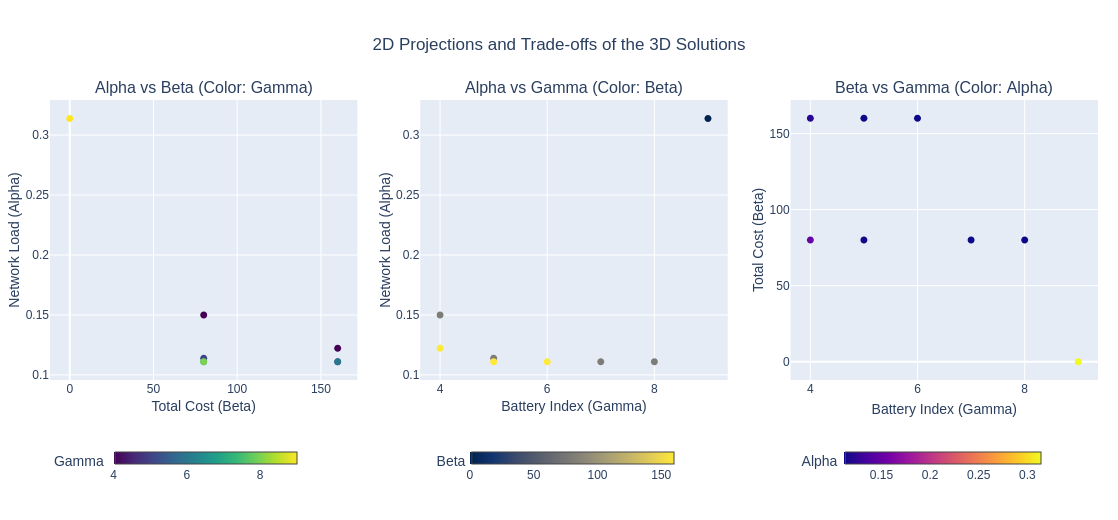

In [93]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# 1. Prepare the solutions dataframe (assuming solutions exists)
df_solutions = pd.DataFrame(solutions, columns=['Network Load (Alpha)', 'Total Cost (Beta)', 'Battery Consumption (Gamma)'])


# 2. Initialize a subplot layout with 1 row and 3 columns
fig_pairs = make_subplots(
    rows=1, cols=3,
    subplot_titles=(
        "Alpha vs Beta (Color: Gamma)", 
        "Alpha vs Gamma (Color: Beta)", 
        "Beta vs Gamma (Color: Alpha)"
    ),
    horizontal_spacing=0.06 # Clean gap between plots
)


# --- PLOT 1: Alpha vs Beta (Beta on X, Alpha on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Total Cost (Beta)'],
        y=df_solutions['Network Load (Alpha)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Battery Consumption (Gamma)'],
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(
                title="Gamma", 
                orientation='h',     
                x=0.12,
                y=-0.22,
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Beta (X): %{x}<br>Alpha (Y): %{y}<br>Gamma: %{marker.color}<extra></extra>"
    ),
    row=1, col=1
)

# --- PLOT 2: Alpha vs Gamma (Gamma on X, Alpha on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Battery Consumption (Gamma)'],
        y=df_solutions['Network Load (Alpha)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Total Cost (Beta)'],
            colorscale='Cividis',
            showscale=True,
            colorbar=dict(
                title="Beta", 
                orientation='h',
                x=0.48, 
                y=-0.22,
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Gamma (X): %{x}<br>Alpha (Y): %{y}<br>Beta: %{marker.color}<extra></extra>"
    ),
    row=1, col=2
)

# --- PLOT 3: Beta vs Gamma (Gamma on X, Beta on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Battery Consumption (Gamma)'],
        y=df_solutions['Total Cost (Beta)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Network Load (Alpha)'],
            colorscale='Plasma',
            showscale=True,
            colorbar=dict(
                title="Alpha", 
                orientation='h',    
                x=0.83,              
                y=-0.22,             
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Gamma (X): %{x}<br>Beta (Y): %{y}<br>Alpha: %{marker.color}<extra></extra>"
    ),
    row=1, col=3
)


# 3. Apply uniform styling and geometry
fig_pairs.update_layout(
    title_text="2D Projections and Trade-offs of the 3D Solutions",
    title_x=0.5, 
    showlegend=False, 
    margin=dict(l=50, r=20, t=100, b=140), 
    width=950, 
    height=520                             
)

# 4. Correct and align all axis titles
fig_pairs.update_xaxes(title_text="Total Cost (Beta)", title_standoff=1, row=1, col=1)
fig_pairs.update_yaxes(title_text="Network Load (Alpha)", title_standoff=1, row=1, col=1)

fig_pairs.update_xaxes(title_text="Battery Index (Gamma)", title_standoff=1, row=1, col=2)
fig_pairs.update_yaxes(title_text="Network Load (Alpha)", title_standoff=1, row=1, col=2)

fig_pairs.update_xaxes(title_text="Battery Index (Gamma)", title_standoff=8, row=1, col=3)
fig_pairs.update_yaxes(title_text="Total Cost (Beta)",title_standoff=1,  row=1, col=3)

fig_pairs.show()

In [94]:
df_solutions

,Network Load (Alpha),Total Cost (Beta),Battery Consumption (Gamma)
0,0.1500,80.0,4.0
1,0.3139,0.0,9.0
2,0.1222,160.0,4.0
3,0.1139,80.0,5.0
4,0.1111,80.0,7.0
5,0.1111,80.0,8.0
6,0.1111,160.0,5.0
7,0.1111,160.0,6.0


 <span style="color:orangered">$\underline{\hspace{ 6 in}}$</span> 

## <font color=darkgreen><b>$\epsilon$-CONTRAINT METHOD</b></font>

This method transforms a multi-objective optimization
problem into a mono-objective optimization problem with additional constraints.
In this approach one of the objectives is minimized while the others are used
as constraints bound by some allowable levels $\epsilon_i$ .

### <font color=blue><b>EXERCISE 3</b></font>.- 
#### Add the objective function and the constraints for applying this method and run it for different values of epsilon. Plot all the resulting points. What values of epsilon do you need to use to obtain all the Pareto Front? 

Now the epsilons values muest be **defined as mutable parameters** in the model (to run an iterative loop):

```python 
# Dynamic parameter bounds for the epsilon-constraint method
model.epsilon_beta = Param(mutable=True, initialize=1000)
model.epsilon_gamma = Param(mutable=True, initialize=1000)
```

#### Indicate which points are part of the Pareto front and why.

### <font color=green><b>Write $\underline{all}$ the model below</b></font>

In [117]:
from pyomo.environ import *
from pyomo.opt import SolverFactory
from pyomo.core import Var

######################
## CREATE THE MODEL ##
######################

model = AbstractModel()

######################
## MODEL PARAMETERS ##
######################

# Set of access networks
model.N = RangeSet(1,NumAccNets)

# Set of mobile devices
model.M = RangeSet(1,NumMobiles)

# Set of services
model.S = RangeSet(1,NumServices)

# Dynamic parameter bounds for the epsilon-constraint method
model.epsilon_beta = Param(mutable=True, initialize=10)
model.epsilon_gamma = Param(mutable=True, initialize=2)

#####################
## MODEL VARIABLES ##
#####################

# y[m,n]=1 if mobile m connects to the network n, and 0 otherwise
model.y = Var(model.M, model.N, within=Binary, initialize=0)

# x[m,n,s]=1 if mobile m connects to the network n to satisfy service s, and 0 otherwise
model.x = Var(model.M, model.N, model.S, within=Binary, initialize=0)

# Maximum load of the networks
model.alpha = Var(within=NonNegativeReals, initialize=0)

# Maximum connection cost to the networks
model.beta  = Var(within=NonNegativeReals, initialize=0)

# Maximum battery consumption indicator from connections to the networks
model.gamma = Var(within=NonNegativeReals, initialize=0)


########################
## OBJECTIVE FUNCTION ##
########################

'''OBJECTIVE FUNCTION 1'''
# Minimize the maximum load of the networks
def Objective1_rule(model):
    return model.alpha
model.Objective1 = Objective(rule=Objective1_rule, sense=minimize)

'''OBJECTIVE FUNCTION 2'''
# Minimize the maximum connection cost to the networks
def Objective2_rule(model):
    return model.beta
model.Objective2 = Objective(rule=Objective2_rule, sense=minimize)

'''OBJECTIVE FUNCTION 3'''
# Minimize the maximum battery consumption of the networks
def Objective3_rule(model):
    return model.gamma
model.Objective3 = Objective(rule=Objective3_rule, sense=minimize)


# ACTIVATE OR DEACTIVATE the objective function according the exercise

model.Objective1.activate()
model.Objective2.deactivate()
model.Objective3.deactivate()

#################
## CONSTRAINTS ##
#################

'''CONSTRAINT 1'''
# Determine if a mobile device connects to a network to satisfy the demand of its services, or not.
def C1_rule(model,m,n):
    return model.y[m,n] <= sum(model.x[m,n,s] for s in model.S if MobInfo[m][Services[s-1]]==1)

model.C1 = Constraint(model.M, model.N,rule=C1_rule)


'''CONSTRAINT 2'''
# For connecting to a network to satisfy one of its service demand, the device
# has to be connected to the network
def C2_rule(model,m,n,s):
    return model.x[m,n,s] <= model.y[m,n] 

model.C2 = Constraint(model.M, model.N, model.S, rule=C2_rule)


'''CONSTRAINT 3'''
# To guarantee the accessibility of the services in every mobile device to one network
def C3_rule(model,m,s):
    if MobInfo[m][Services[s-1]]==1:
        return sum(model.x[m,n,s] for n in model.N)==1
    else:
        return Constraint.Skip

model.C3 = Constraint(model.M, model.S,rule=C3_rule)


'''CONSTRAINT 4'''
# To guarantee that the services being used can only be provided by networks with enough 
# bandwidth to meet its demand, not overloading any network.
def C4_rule(model,m,n,s):
    if MobInfo[m][Services[s-1]]==1:
        return Demand[s-1]*model.x[m,n,s] <= BW[s-1]
    else:
        return Constraint.Skip

model.C4 = Constraint(model.M, model.N, model.S, rule=C4_rule)


'''CONSTRAINT 5'''
# To guarantee that the connection cost to a network does not exceed the maximum connection
#cost established by the user of the mobile device
def C5_rule(model,m,n):
    if Cost[n-1] !=0:
        return Cost[n-1]*model.y[m,n] <= MobInfo[m]['maxcost']
    else:
        return Constraint.Skip

model.C5 = Constraint(model.M, model.N, rule=C5_rule)


'''CONSTRAINT 6'''
# To ensure that the consumption indicator generated by the connection to a network 
# does not exceed the battery level of a mobile device.
def C6_rule(model,m,n):
    return PowerConsumption[m-1][n-1]*model.y[m,n] <= Battery[m-1]

model.C6 = Constraint(model.M, model.N, rule=C6_rule)


'''CONSTRAINT 7'''
# To guarantee the connection of a mobile device to a reachable network.
def C7_rule(model,m,n):
    return ms*model.y[m,n] <= SignalInfo[m][n-1]

model.C7 = Constraint(model.M, model.N, rule=C7_rule)


'''CONSTRAINT 8'''
# To calculate the maximum load of the available networks.
def C8_rule(model,n):
    return sum((Demand[s-1]/BW[s-1])*model.x[m,n,s]for m in model.M \
               for s in model.S if MobInfo[m][Services[s-1]]==1) <= model.alpha

model.C8 = Constraint(model.N, rule=C8_rule)


'''CONSTRAINT 9'''
# To calculate the maximum connection cost to the networks.
def C9_rule(model,n):
    return sum(Cost[n-1]*model.y[m,n] for m in model.M) <= model.beta

model.C9 = Constraint(model.N, rule=C9_rule)


'''CONSTRAINT 10'''
# To calculate the maximum power consumption indicator due to connection to networks.
def C10_rule(model,n):
    return sum(PowerConsumption[m-1][n-1]*model.y[m,n] for m in model.M)<= model.gamma

model.C10 = Constraint(model.N, rule=C10_rule)

'''CONSTRAINT 11'''
# To claculate the beta constraint for epsilon constraint
def beta_rule(model):
    return model.beta <= model.epsilon_beta

model.beta_constraint = Constraint(rule=beta_rule)

'''CONSTRAINT 12'''
# To claculate the gamma constraint for epsilon constraint
def gamma_rule(model):
    return model.gamma <= model.epsilon_gamma

model.gamma_constraint = Constraint(rule=gamma_rule)

### <font color=green><b>Use the following code to execute the model with different values of epsilons</b></font>

In [118]:
############################# ITERATIVE LOOP TO GENERATE SOLUTIONS #############################

# Construct the instance of the model and pass it to an (external) solver, in this case GLPK
opt = SolverFactory('glpk')
instance = model.create_instance()

# Define grid search limits based on maximum possible beta (cost) and gamma (battery)
# You can decrease the step sizes (e.g., to 10 or 1) to get a denser plot

beta_grid = range(0, 401, 20)    # Cost axis grid points
gamma_grid = range(0, 16, 1)     # Battery axis grid points

solutions = []

print("Sweeping objective space to find different solutions...")

for b in beta_grid:
    for g in gamma_grid:
        # Dynamically inject the new upper thresholds into the current instance
        instance.epsilon_beta.value = b
        instance.epsilon_gamma.value = g
        
        results = opt.solve(instance)
        
        # Check if the GLPK solver successfully found an optimal, feasible combination
        if (results.solver.status == SolverStatus.ok) and (results.solver.termination_condition == TerminationCondition.optimal):
            alpha_opt = value(instance.alpha)
            beta_opt = value(instance.beta)
            gamma_opt = value(instance.gamma)
            
            # Formulate the coordinates tuple and avoid duplicate allocations
            point = (round(alpha_opt, 4), round(beta_opt, 4), round(gamma_opt, 4))
            if point not in solutions:
                solutions.append(point)

print(f"Process complete! Found {len(solutions)} distinct solutions.")


Sweeping objective space to find different solutions...
Process complete! Found 17 distinct solutions.


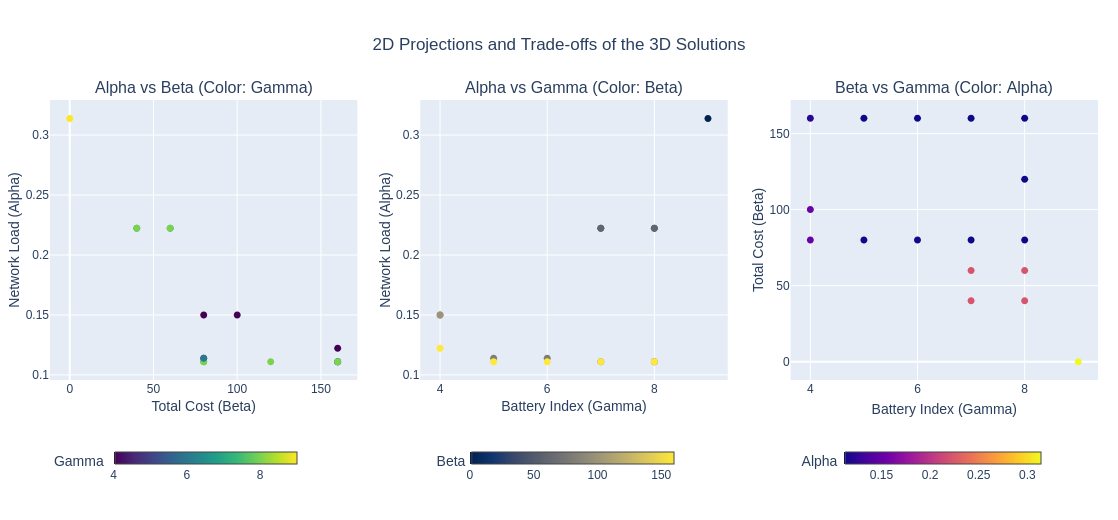

In [119]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# 1. Prepare the solutions dataframe (assuming solutions exists)
df_solutions = pd.DataFrame(solutions, columns=['Network Load (Alpha)', 'Total Cost (Beta)', 'Battery Consumption (Gamma)'])


# 2. Initialize a subplot layout with 1 row and 3 columns
fig_pairs = make_subplots(
    rows=1, cols=3,
    subplot_titles=(
        "Alpha vs Beta (Color: Gamma)", 
        "Alpha vs Gamma (Color: Beta)", 
        "Beta vs Gamma (Color: Alpha)"
    ),
    horizontal_spacing=0.06 # Clean gap between plots
)


# --- PLOT 1: Alpha vs Beta (Beta on X, Alpha on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Total Cost (Beta)'],
        y=df_solutions['Network Load (Alpha)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Battery Consumption (Gamma)'],
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(
                title="Gamma", 
                orientation='h',     
                x=0.12,
                y=-0.22,
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Beta (X): %{x}<br>Alpha (Y): %{y}<br>Gamma: %{marker.color}<extra></extra>"
    ),
    row=1, col=1
)

# --- PLOT 2: Alpha vs Gamma (Gamma on X, Alpha on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Battery Consumption (Gamma)'],
        y=df_solutions['Network Load (Alpha)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Total Cost (Beta)'],
            colorscale='Cividis',
            showscale=True,
            colorbar=dict(
                title="Beta", 
                orientation='h',
                x=0.48, 
                y=-0.22,
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Gamma (X): %{x}<br>Alpha (Y): %{y}<br>Beta: %{marker.color}<extra></extra>"
    ),
    row=1, col=2
)

# --- PLOT 3: Beta vs Gamma (Gamma on X, Beta on Y) ---
fig_pairs.add_trace(
    go.Scatter(
        x=df_solutions['Battery Consumption (Gamma)'],
        y=df_solutions['Total Cost (Beta)'],
        mode='markers',
        marker=dict(
            size=7,
            color=df_solutions['Network Load (Alpha)'],
            colorscale='Plasma',
            showscale=True,
            colorbar=dict(
                title="Alpha", 
                orientation='h',    
                x=0.83,              
                y=-0.22,             
                yanchor='top',
                thickness=12, 
                len=0.25
            )
        ),
        hovertemplate="Gamma (X): %{x}<br>Beta (Y): %{y}<br>Alpha: %{marker.color}<extra></extra>"
    ),
    row=1, col=3
)


# 3. Apply uniform styling and geometry
fig_pairs.update_layout(
    title_text="2D Projections and Trade-offs of the 3D Solutions",
    title_x=0.5, 
    showlegend=False, 
    margin=dict(l=50, r=20, t=100, b=140), 
    width=950, 
    height=520                             
)

# 4. Correct and align all axis titles
fig_pairs.update_xaxes(title_text="Total Cost (Beta)", title_standoff=1, row=1, col=1)
fig_pairs.update_yaxes(title_text="Network Load (Alpha)", title_standoff=1, row=1, col=1)

fig_pairs.update_xaxes(title_text="Battery Index (Gamma)", title_standoff=1, row=1, col=2)
fig_pairs.update_yaxes(title_text="Network Load (Alpha)", title_standoff=1, row=1, col=2)

fig_pairs.update_xaxes(title_text="Battery Index (Gamma)", title_standoff=8, row=1, col=3)
fig_pairs.update_yaxes(title_text="Total Cost (Beta)",title_standoff=1,  row=1, col=3)

fig_pairs.show()

In [120]:
df_solutions

,Network Load (Alpha),Total Cost (Beta),Battery Consumption (Gamma)
0,0.3139,0.0,9.0
1,0.2222,40.0,7.0
2,0.2222,40.0,8.0
3,0.2222,60.0,7.0
4,0.2222,60.0,8.0
5,0.1500,80.0,4.0
6,0.1139,80.0,5.0
7,0.1111,80.0,7.0
8,0.1111,80.0,8.0
9,0.1500,100.0,4.0


 <span style="color:orangered">$\underline{\hspace{ 6 in}}$</span> 

## <font color=darkgreen><b>GOL PROGRAMMING METHOD</b></font>

This method is a technique often used in engineering design to find a compromised solution which will simultaneosly satisfy a number of design goals. This problem is reduced into a single objective of minimizing a weighted sum of deviations from goals. 

### <font color=blue><b>EXERCISE 4</b></font>.- 
#### Formulate the problem and run it for different values of weight w. Plot all the resulting points. What are the goals in this case?

#### Indicate which points are part of the Pareto front and why.

### <font color=green><b>Write $\underline{all}$ the model below</b></font>

In [ ]:
from pyomo.environ import *
from pyomo.opt import SolverFactory
from pyomo.core import Var

######################
## CREATE THE MODEL ##
######################

model = AbstractModel()

######################
## MODEL PARAMETERS ##
######################

# Set of access networks
model.N = RangeSet(1,NumAccNets)

# Set of mobile devices
model.M = RangeSet(1,NumMobiles)

# Set of services
model.S = RangeSet(1,NumServices)

model.F_alpha = Param(initialize=0.1111)
model.F_beta = Param(initialize=0)
model.F_gamma = Param(initialize=4)

model.w_alpha = Param(initialize=0.4, mutable=True)
model.w_beta = Param(initialize=0.3, mutable=True)
model.w_gamma = Param(initialize=0.3, mutable=True)

#####################
## MODEL VARIABLES ##
#####################

# y[m,n]=1 if mobile m connects to the network n, and 0 otherwise
model.y = Var(model.M, model.N, within=Binary, initialize=0)

# x[m,n,s]=1 if mobile m connects to the network n to satisfy service s, and 0 otherwise
model.x = Var(model.M, model.N, model.S, within=Binary, initialize=0)

# Maximum load of the networks
model.alpha = Var(within=NonNegativeReals, initialize=0)

# Maximum connection cost to the networks
model.beta  = Var(within=NonNegativeReals, initialize=0)

# Maximum battery consumption indicator from connections to the networks
model.gamma = Var(within=NonNegativeReals, initialize=0)

# Positive deviations from goals
model.z_alpha = Var(within=NonNegativeReals)
model.z_beta = Var(within=NonNegativeReals)
model.z_gamma = Var(within=NonNegativeReals)


########################
## OBJECTIVE FUNCTION ##
########################

'''OBJECTIVE FUNCTION 1'''
# Minimize the maximum load of the networks
def Objective1_rule(model):
    return model.alpha
model.Objective1 = Objective(rule=Objective1_rule, sense=minimize)

'''OBJECTIVE FUNCTION 2'''
# Minimize the maximum connection cost to the networks
def Objective2_rule(model):
    return model.beta
model.Objective2 = Objective(rule=Objective2_rule, sense=minimize)

'''OBJECTIVE FUNCTION 3'''
# Minimize the maximum battery consumption of the networks
def Objective3_rule(model):
    return model.gamma
model.Objective3 = Objective(rule=Objective3_rule, sense=minimize)

'''OBJECTIVE FUNCTION 5 - GOAL PROGRAMMING'''

def Objective5_rule(model):
    return (model.w_alpha * model.z_alpha / 0.3139 + model.w_beta * model.z_beta / 160 + model.w_gamma * model.z_gamma / 10)

model.Objective5 = Objective(rule=Objective5_rule, sense=minimize)


# ACTIVATE OR DEACTIVATE the objective function according the exercise

model.Objective1.deactivate()
model.Objective2.deactivate()
model.Objective3.deactivate()
model.Objective5.activate()

#################
## CONSTRAINTS ##
#################

'''CONSTRAINT 1'''
# Determine if a mobile device connects to a network to satisfy the demand of its services, or not.
def C1_rule(model,m,n):
    return model.y[m,n] <= sum(model.x[m,n,s] for s in model.S if MobInfo[m][Services[s-1]]==1)

model.C1 = Constraint(model.M, model.N,rule=C1_rule)


'''CONSTRAINT 2'''
# For connecting to a network to satisfy one of its service demand, the device
# has to be connected to the network
def C2_rule(model,m,n,s):
    return model.x[m,n,s] <= model.y[m,n] 

model.C2 = Constraint(model.M, model.N, model.S, rule=C2_rule)


'''CONSTRAINT 3'''
# To guarantee the accessibility of the services in every mobile device to one network
def C3_rule(model,m,s):
    if MobInfo[m][Services[s-1]]==1:
        return sum(model.x[m,n,s] for n in model.N)==1
    else:
        return Constraint.Skip

model.C3 = Constraint(model.M, model.S,rule=C3_rule)


'''CONSTRAINT 4'''
# To guarantee that the services being used can only be provided by networks with enough 
# bandwidth to meet its demand, not overloading any network.
def C4_rule(model,m,n,s):
    if MobInfo[m][Services[s-1]]==1:
        return Demand[s-1]*model.x[m,n,s] <= BW[s-1]
    else:
        return Constraint.Skip

model.C4 = Constraint(model.M, model.N, model.S, rule=C4_rule)


'''CONSTRAINT 5'''
# To guarantee that the connection cost to a network does not exceed the maximum connection
#cost established by the user of the mobile device
def C5_rule(model,m,n):
    if Cost[n-1] !=0:
        return Cost[n-1]*model.y[m,n] <= MobInfo[m]['maxcost']
    else:
        return Constraint.Skip

model.C5 = Constraint(model.M, model.N, rule=C5_rule)


'''CONSTRAINT 6'''
# To ensure that the consumption indicator generated by the connection to a network 
# does not exceed the battery level of a mobile device.
def C6_rule(model,m,n):
    return PowerConsumption[m-1][n-1]*model.y[m,n] <= Battery[m-1]

model.C6 = Constraint(model.M, model.N, rule=C6_rule)


'''CONSTRAINT 7'''
# To guarantee the connection of a mobile device to a reachable network.
def C7_rule(model,m,n):
    return ms*model.y[m,n] <= SignalInfo[m][n-1]

model.C7 = Constraint(model.M, model.N, rule=C7_rule)


'''CONSTRAINT 8'''
# To calculate the maximum load of the available networks.
def C8_rule(model,n):
    return sum((Demand[s-1]/BW[s-1])*model.x[m,n,s]for m in model.M \
               for s in model.S if MobInfo[m][Services[s-1]]==1) <= model.alpha

model.C8 = Constraint(model.N, rule=C8_rule)


'''CONSTRAINT 9'''
# To calculate the maximum connection cost to the networks.
def C9_rule(model,n):
    return sum(Cost[n-1]*model.y[m,n] for m in model.M) <= model.beta

model.C9 = Constraint(model.N, rule=C9_rule)


'''CONSTRAINT 10'''
# To calculate the maximum power consumption indicator due to connection to networks.
def C10_rule(model,n):
    return sum(PowerConsumption[m-1][n-1]*model.y[m,n] for m in model.M)<= model.gamma

model.C10 = Constraint(model.N, rule=C10_rule)

# GOAL CONSTRAINTS

def goal_alpha_rule(model):
    return model.alpha - model.z_alpha <= model.F_alpha

model.goal_alpha = Constraint(rule=goal_alpha_rule)

def goal_beta_rule(model):
    return model.beta - model.z_beta <= model.F_beta

model.goal_beta = Constraint(rule=goal_beta_rule)

def goal_gamma_rule(model):
    return model.gamma - model.z_gamma <= model.F_gamma

model.goal_gamma = Constraint(rule=goal_gamma_rule)